# NAME : JONATHAN AMEGBOR
# ID:    202520493

# UK TRAFFIC ACCIDENT DATA

In [1]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from scipy import stats
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller
from xgboost import XGBRegressor

print('All libraries imported successfully')

All libraries imported successfully


In [2]:
# ── Reusable helper functions ──────────────────────────────────────────────

def chi2_uniform_test(counts, df_value, label=''):
    """
    Chi-squared goodness-of-fit test against uniform distribution.
    Returns a one-row DataFrame with chi2, df and p-value.
    """
    chi2, p = stats.chisquare(counts)
    return pd.DataFrame({
        'Test':    [label],
        'chi2':    [round(chi2, 1)],
        'df':      [df_value],
        'p_value': [f'{p:.2e}']
    })


def compute_metrics(actual, predicted, label=''):
    """
    Compute MSE, RMSE and MAPE for time series evaluation.
    Returns a one-row DataFrame.
    """
    actual    = np.array(actual)
    predicted = np.array(predicted)
    mse  = mean_squared_error(actual, predicted)
    rmse = np.sqrt(mse)
    mask = actual != 0
    mape = np.mean(np.abs((actual[mask] - predicted[mask]) / actual[mask])) * 100
    return pd.DataFrame({
        'Model':    [label],
        'MSE':      [round(mse,  2)],
        'RMSE':     [round(rmse, 2)],
        'MAPE (%)': [round(mape, 2)]
    })


def install_package(package_name):
    """
    Install a pip package programmatically if not already available.
    """
    import subprocess
    subprocess.run(['pip', 'install', package_name, '--quiet'], check=True)
    print(f'{package_name} installed successfully')


print('Helper functions defined')

Helper functions defined


#  TASK 1
## Temporal Analysis: Hours of Day and Days of Week
Investigating whether accidents are significantly more likely at particular hours and days using chi-squared goodness-of-fit tests.

In [3]:
DB_PATH = 'accident_data_v1.0.0_2023.db'

# Load the 2018 Accident Data

In [4]:
with sqlite3.connect(DB_PATH) as con:
    df = pd.read_sql(
        "SELECT time, day_of_week FROM accident WHERE accident_year = 2018;",
        con,
    )

# Extract hour from "HH:MM" and label days (1=Sun ... 7=Sat in this database)
df['hour'] = df['time'].str.slice(0, 2).astype(int)
dow_map = {1:'Sun', 2:'Mon', 3:'Tue', 4:'Wed', 5:'Thu', 6:'Fri', 7:'Sat'}
df['dow_label'] = df['day_of_week'].map(dow_map)

print(f"Loaded {len(df):,} accidents from 2018")
df.head()

Loaded 122,635 accidents from 2018


,time,day_of_week,hour,dow_label
0,01:30,2,1,Mon
1,00:50,2,0,Mon
2,00:45,2,0,Mon
3,03:00,2,3,Mon
4,02:20,2,2,Mon


In [5]:
# Check for missing values in the columns used
missing = pd.DataFrame({
    'time_missing': [(df['time'].isna() | (df['time'] == '') | (df['time'] == '-1')).sum()],
    'dow_missing':  [(df['day_of_week'].isna() | (df['day_of_week'] == -1)).sum()],
    'total_rows':   [len(df)],
})
print(missing.to_string(index=False))

 time_missing  dow_missing  total_rows
            0            0      122635


## Accidents by day of week

**H₀:** accidents are uniformly distributed across the 7 days.
A χ² goodness-of-fit test against a uniform null tells us whether the observed distribution differs significantly from "no pattern".

In [6]:
# Aggregate accident counts by day of week (1=Sun ... 7=Sat in this database)
dow_map = {1:'Sun', 2:'Mon', 3:'Tue', 4:'Wed', 5:'Thu', 6:'Fri', 7:'Sat'}

dow_counts = (
    df.groupby('day_of_week')
      .size()
      .reset_index(name='no_of_accidents')
)
dow_counts['day_name'] = dow_counts['day_of_week'].map(dow_map)

# Reorder so day_name sits between the code and the count
dow_counts = dow_counts[['day_of_week', 'day_name', 'no_of_accidents']]
dow_counts

,day_of_week,day_name,no_of_accidents
0,1,Sun,13801
1,2,Mon,17740
2,3,Tue,17950
3,4,Wed,18397
4,5,Thu,18656
5,6,Fri,20021
6,7,Sat,16070


In [7]:
# chi2 goodness-of-fit test against uniform expectation
chi2_uniform_test(
    dow_counts['no_of_accidents'].values,
    df_value=6,
    label='Day of week — uniform test'
)

,Test,chi2,df,p_value
0,Day of week — uniform test,1397.4,6,8.87e-299


## Accidents by hour of day

In [8]:
# Aggregate accident counts by hour of day
hour_counts = (
    df.groupby('hour')
      .size()
      .reset_index(name='no_of_accidents')
)
hour_counts

,hour,no_of_accidents
0,0,1850
1,1,1267
2,2,1053
3,3,835
4,4,798
5,5,1198
6,6,2481
7,7,5638
8,8,8538
9,9,5875


In [9]:
# chi2 goodness-of-fit test against uniform expectation
chi2_uniform_test(
    hour_counts['no_of_accidents'].values,
    df_value=23,
    label='Hour of day — uniform test'
)

,Test,chi2,df,p_value
0,Hour of day — uniform test,44844.9,23,0.00e+00


## Accidents by day of week AND hour of day

This is the joint distribution table;every (day, hour) combination with its accident count.

In [10]:
# Joint table: counts by (day_of_week, hour)
joint_long = (
    df.groupby(['day_of_week', 'hour'])
      .size()
      .reset_index(name='no_of_accidents')
)
joint_long.head()

,day_of_week,hour,no_of_accidents
0,1,0,493
1,1,1,369
2,1,2,321
3,1,3,270
4,1,4,203


##  Heatmap of hour × day of week

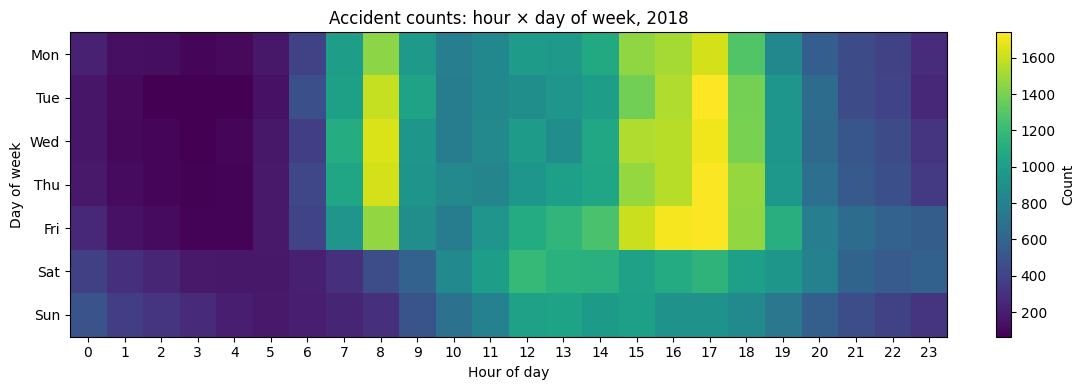

In [11]:
# Pivot the long-form table to a wide grid for the heatmap
joint_wide = joint_long.pivot(index='day_of_week', columns='hour', values='no_of_accidents')

# Re-label the y-axis with weekday names (Monday first, in plotting order)
dow_map = {1:'Sun', 2:'Mon', 3:'Tue', 4:'Wed', 5:'Thu', 6:'Fri', 7:'Sat'}
plot_order = [2, 3, 4, 5, 6, 7, 1]   # Mon ... Sun
joint_wide = joint_wide.reindex(plot_order)

fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(joint_wide.values, aspect='auto', cmap='viridis')
ax.set_xticks(range(24))
ax.set_xticklabels(range(24))
ax.set_yticks(range(7))
ax.set_yticklabels([dow_map[c] for c in plot_order])
ax.set_xlabel('Hour of day')
ax.set_ylabel('Day of week')
ax.set_title('Accident counts: hour × day of week, 2018')
cbar = plt.colorbar(im, ax=ax, fraction=0.04)
cbar.set_label('Count')
plt.tight_layout()
plt.savefig('task1_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

## Weekday vs weekend hourly profile

Comparing raw hourly counts of weekdays and weekends is misleading because there are 5 weekdays and only 2 weekend days each week. We normalise by the actual number of weekday/weekend days in 2018 to get *mean accidents per day at each hour*. This reveals the structural difference between commuter and leisure travel patterns.

In [12]:
# Count weekdays and weekend days in 2018
all_dates = pd.date_range('2018-01-01', '2018-12-31')
n_wd = sum(1 for d in all_dates if d.weekday() < 5)   # Mon-Fri
n_we = sum(1 for d in all_dates if d.weekday() >= 5)  # Sat-Sun

is_weekend = df['day_of_week'].isin([1, 7])  # Sat=7, Sun=1
weekday_rate = df[~is_weekend].groupby('hour').size() / n_wd
weekend_rate = df[ is_weekend].groupby('hour').size() / n_we

# Combined per-hour rate table
rate_table = pd.DataFrame({
    'hour':            weekday_rate.index,
    'weekday_per_day': weekday_rate.values.round(1),
    'weekend_per_day': weekend_rate.values.round(1),
})
rate_table

,hour,weekday_per_day,weekend_per_day
0,0,3.7,8.4
1,1,2.3,6.4
2,2,1.9,5.4
3,3,1.5,4.3
4,4,1.6,3.6
5,5,3.2,3.4
6,6,7.9,4.0
7,7,19.6,5.1
8,8,29.8,7.2
9,9,18.3,10.5


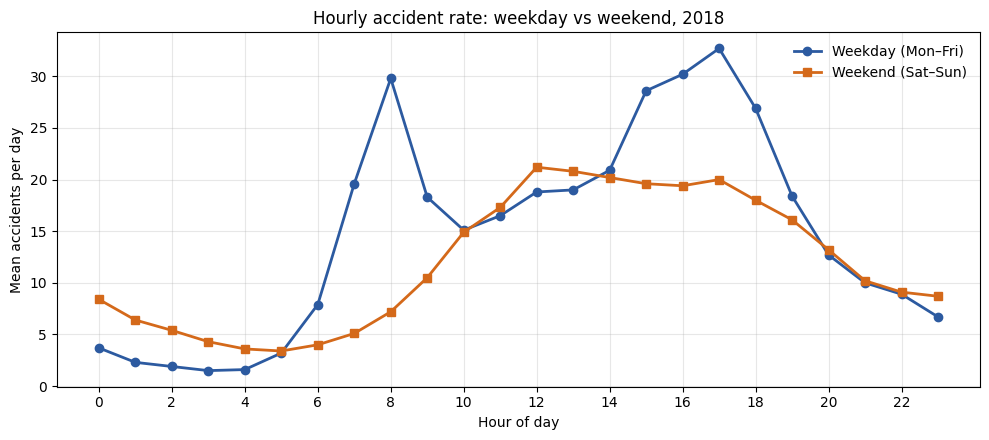

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(rate_table['hour'], rate_table['weekday_per_day'],
        marker='o', label='Weekday (Mon–Fri)', color='#2c5aa0', linewidth=2)
ax.plot(rate_table['hour'], rate_table['weekend_per_day'],
        marker='s', label='Weekend (Sat–Sun)', color='#d4691a', linewidth=2)
ax.set_xlabel('Hour of day')
ax.set_ylabel('Mean accidents per day')
ax.set_title('Hourly accident rate: weekday vs weekend, 2018')
ax.set_xticks(range(0, 24, 2))
ax.legend(frameon=False)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('task1_weekday_vs_weekend.png', dpi=150, bbox_inches='tight')
plt.show()

# TASK 2

# Load motorbike data and map to three categories

In [14]:
# Motorbike accident temporal analysis
# Vehicle codes per STATS20: 02=≤50cc, 03=51–125cc, 04=126–500cc, 05=>500cc
#"125cc and under" = codes 02+03 combined; 97 (unknown cc) and 23 (electric) dropped

MOTO_CODES = [2, 3, 4, 5]

CAT_MAP = {
    2: '125cc and under',
    3: '125cc and under',
    4: '126cc to 500cc',
    5: 'Over 500cc'
}

with sqlite3.connect(DB_PATH) as con:
    moto = pd.read_sql(
        """
        SELECT v.accident_index,
               v.vehicle_type,
               a.time,
               a.day_of_week
        FROM vehicle v
        JOIN accident a ON v.accident_index = a.accident_index
        WHERE a.accident_year = 2018
          AND v.vehicle_type IN (2, 3, 4, 5);
        """,
        con,
    )

moto['category'] = moto['vehicle_type'].map(CAT_MAP)
moto['hour'] = moto['time'].str[:2].astype(int)

print(f"Total motorbike accident records: {len(moto):,}")
moto.head()

Total motorbike accident records: 17,478


,accident_index,vehicle_type,time,day_of_week,category,hour
0,2018010080990,3,00:30,2,125cc and under,0
1,2018010080992,2,03:00,2,125cc and under,3
2,2018010080996,3,03:05,2,125cc and under,3
3,2018010081002,5,07:00,2,Over 500cc,7
4,2018010081009,3,10:35,2,125cc and under,10


# Per-category counts (sanity check table)

In [15]:
# Per-category record counts
cat_counts = (
    moto.groupby('category')
        .size()
        .reset_index(name='no_of_accidents')
)
cat_counts

,category,no_of_accidents
0,125cc and under,9362
1,126cc to 500cc,2240
2,Over 500cc,5876


# Hour-of-day aggregation by category

In [16]:
# Hour-of-day counts per category
hour_cat = (
    moto.groupby(['category', 'hour'])
        .size()
        .reset_index(name='no_of_accidents')
)

# Pivot for readability — rows=hour, columns=category
hour_pivot = hour_cat.pivot(index='hour', columns='category', values='no_of_accidents').fillna(0).astype(int)
hour_pivot.columns.name = None
hour_pivot = hour_pivot.reset_index()
hour_pivot

,hour,125cc and under,126cc to 500cc,Over 500cc
0,0,123,23,29
1,1,72,11,24
2,2,39,5,15
3,3,37,6,10
4,4,20,8,15
5,5,81,21,41
6,6,187,57,154
7,7,475,134,335
8,8,578,142,382
9,9,324,102,225


# χ² uniformity tests per category (hour of day)

In [17]:
# χ² goodness-of-fit against uniform null — one test per category
categories = ['125cc and under', '126cc to 500cc', 'Over 500cc']

hour_chi2_results = []
for cat in categories:
    counts = hour_pivot[cat].values
    chi2, p = stats.chisquare(counts)
    hour_chi2_results.append({
        'category': cat,
        'n': counts.sum(),
        'chi2': round(chi2, 1),
        'df': 23,
        'p_value': f'{p:.2e}'
    })

pd.DataFrame(hour_chi2_results)

,category,n,chi2,df,p_value
0,125cc and under,9362,3920.6,23,0.00e+00
1,126cc to 500cc,2240,1067.0,23,7.42e-211
2,Over 500cc,5876,3297.0,23,0.00e+00


In [18]:
# Day-of-week counts per category
dow_map = {1:'Sun', 2:'Mon', 3:'Tue', 4:'Wed', 5:'Thu', 6:'Fri', 7:'Sat'}

dow_cat = (
    moto.groupby(['category', 'day_of_week'])
        .size()
        .reset_index(name='no_of_accidents')
)
dow_cat['day_name'] = dow_cat['day_of_week'].map(dow_map)

dow_pivot = dow_cat.pivot(index='day_of_week', columns='category', values='no_of_accidents').fillna(0).astype(int)
dow_pivot.columns.name = None
dow_pivot = dow_pivot.reset_index()
dow_pivot['day_name'] = dow_pivot['day_of_week'].map(dow_map)
dow_pivot = dow_pivot[['day_of_week', 'day_name', '125cc and under', '126cc to 500cc', 'Over 500cc']]

# χ² uniformity tests per category
dow_chi2_results = []
for cat in categories:
    counts = dow_pivot[cat].values
    chi2, p = stats.chisquare(counts)
    dow_chi2_results.append({
        'category': cat,
        'chi2': round(chi2, 1),
        'df': 6,
        'p_value': f'{p:.2e}'
    })

print("Day-of-week distribution:")
display(dow_pivot)
print("\nχ² uniformity tests:")
pd.DataFrame(dow_chi2_results)

Day-of-week distribution:


,day_of_week,day_name,125cc and under,126cc to 500cc,Over 500cc
0,1,Sun,972,259,885
1,2,Mon,1271,309,772
2,3,Tue,1359,323,755
3,4,Wed,1459,315,837
4,5,Thu,1495,363,915
5,6,Fri,1595,371,906
6,7,Sat,1211,300,806



χ² uniformity tests:


,category,chi2,df,p_value
0,125cc and under,194.7,6,2.59e-39
1,126cc to 500cc,27.3,6,1.29e-04
2,Over 500cc,29.8,6,4.28e-05


# χ² test of homogeneity (the comparative test)

In [19]:
# χ² test of homogeneity — hour × category contingency table
# Tests whether the three categories share the same hourly distribution
hour_contingency = hour_pivot.set_index('hour')[categories].values

chi2_h, p_h, dof_h, _ = stats.chi2_contingency(hour_contingency)
print(f"Hour homogeneity test: χ²({dof_h}) = {chi2_h:,.1f}, p = {p_h:.2e}")

# Same test for day of week
dow_contingency = dow_pivot.set_index('day_of_week')[categories].values

chi2_d, p_d, dof_d, _ = stats.chi2_contingency(dow_contingency)
print(f"Day homogeneity test:  χ²({dof_d}) = {chi2_d:,.1f}, p = {p_d:.2e}")

Hour homogeneity test: χ²(46) = 389.6, p = 5.87e-56
Day homogeneity test:  χ²(12) = 87.9, p = 1.23e-13


# Visualisation 

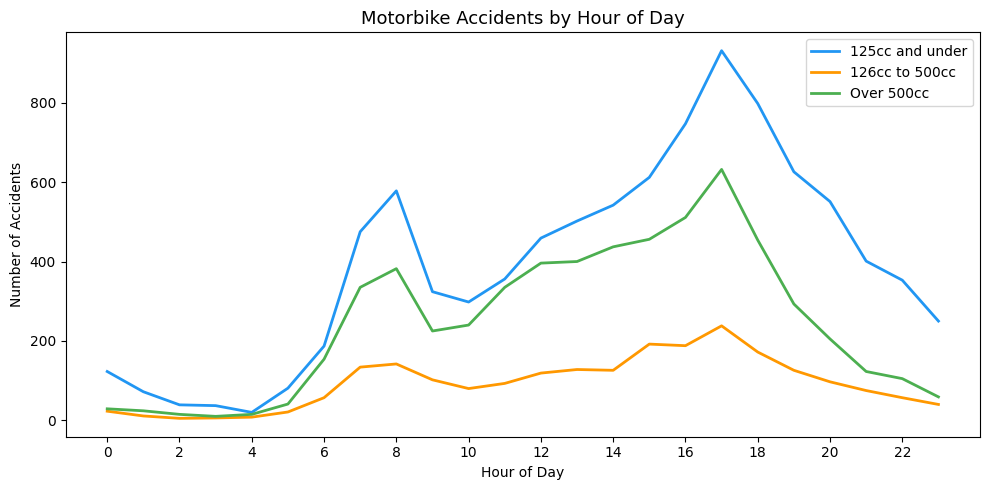

In [21]:
fig, ax = plt.subplots(figsize=(10, 5))

colours = {'125cc and under': '#2196F3', '126cc to 500cc': '#FF9800', 'Over 500cc': '#4CAF50'}

for cat in categories:
    ax.plot(hour_pivot['hour'], hour_pivot[cat], label=cat, color=colours[cat], linewidth=2)

ax.set_title('Motorbike Accidents by Hour of Day', fontsize=13)
ax.set_xlabel('Hour of Day')
ax.set_ylabel('Number of Accidents')
ax.set_xticks(range(0, 24, 2))
ax.legend()

plt.tight_layout()
plt.savefig('task2_motorbike_hourly.png', dpi=150, bbox_inches='tight')
plt.show()

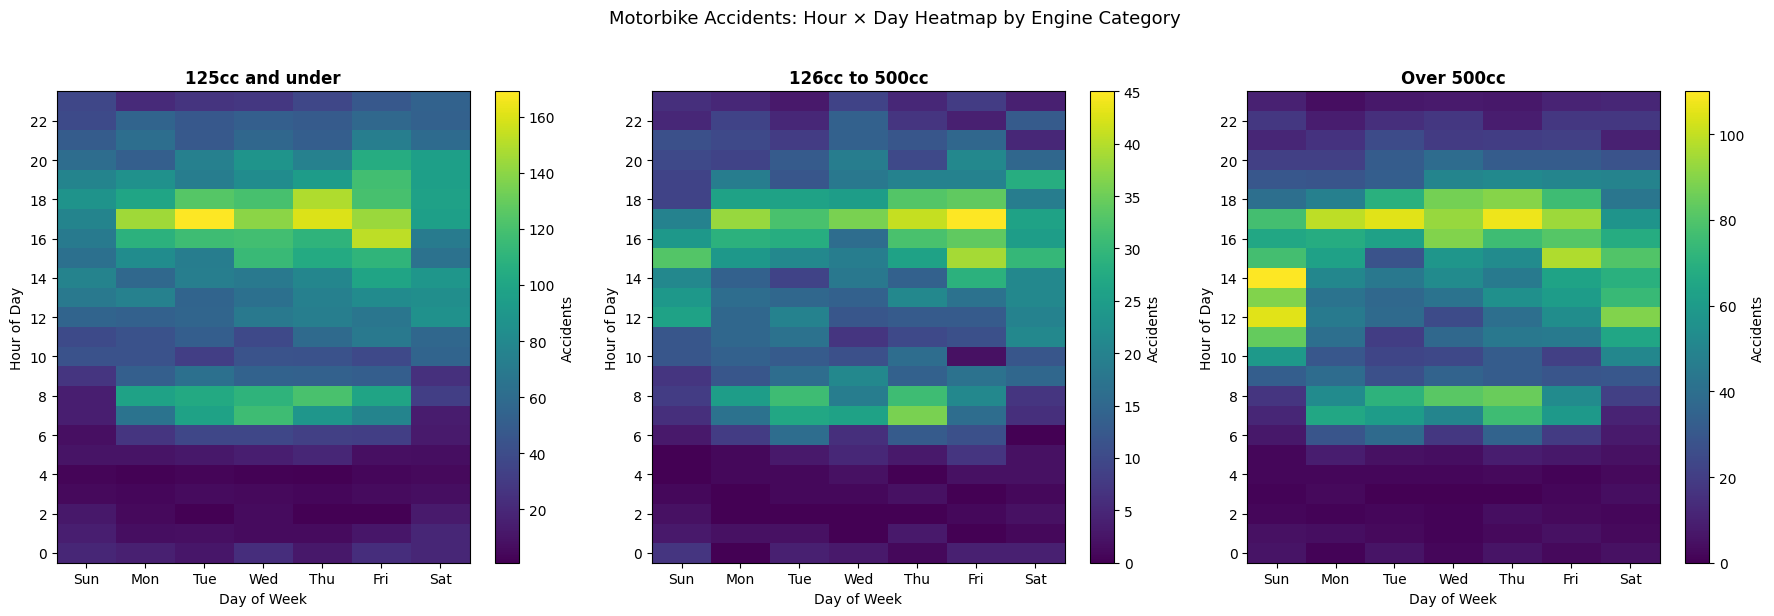

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, cat in zip(axes, categories):
    # Build hour × day matrix
    subset = moto[moto['category'] == cat]
    heat_data = (
        subset.groupby(['hour', 'day_of_week'])
              .size()
              .reset_index(name='count')
              .pivot(index='hour', columns='day_of_week', values='count')
              .fillna(0)
    )
    heat_data.columns = ['Sun','Mon','Tue','Wed','Thu','Fri','Sat']

    im = ax.imshow(heat_data, aspect='auto', cmap='viridis', origin='lower')
    ax.set_title(cat, fontsize=12, fontweight='bold')
    ax.set_xlabel('Day of Week')
    ax.set_ylabel('Hour of Day')
    ax.set_xticks(range(7))
    ax.set_xticklabels(['Sun','Mon','Tue','Wed','Thu','Fri','Sat'])
    ax.set_yticks(range(0, 24, 2))
    ax.set_yticklabels(range(0, 24, 2))
    plt.colorbar(im, ax=ax, label='Accidents')

plt.suptitle('Motorbike Accidents: Hour × Day Heatmap by Engine Category', 
             fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('task2_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

# Findings summary table

In [23]:
# Summary statistics
summary = pd.DataFrame({
    'Category': categories,
    'Total accidents': [9362, 2240, 5876],
    'Peak hour': [17, 17, 17],
    'Peak day': ['Fri', 'Fri', 'Fri'],
    'Hour χ²(23)': [3920.6, 1067.0, 3297.0],
    'Day χ²(6)': [194.7, 27.3, 29.8],
    'Hour p': ['<0.001', '<0.001', '<0.001'],
    'Day p': ['<0.001', '<0.001', '<0.001']
})
summary

,Category,Total accidents,Peak hour,Peak day,Hour χ²(23),Day χ²(6),Hour p,Day p
0,125cc and under,9362,17,Fri,3920.6,194.7,<0.001,<0.001
1,126cc to 500cc,2240,17,Fri,1067.0,27.3,<0.001,<0.001
2,Over 500cc,5876,17,Fri,3297.0,29.8,<0.001,<0.001


# TASK 3

# Load pedestrian casualty data

In [25]:
# Pedestrian accident temporal analysis
# casualty_class = 3 identifies pedestrians in the casualty table

with sqlite3.connect(DB_PATH) as con:
    ped = pd.read_sql(
        """
        SELECT c.accident_index,
               c.casualty_class,
               a.time,
               a.day_of_week
        FROM casualty c
        JOIN accident a ON c.accident_index = a.accident_index
        WHERE a.accident_year = 2018
          AND c.casualty_class = 3;
        """,
        con,
    )

ped['hour'] = ped['time'].str[:2].astype(int)

print(f"Total pedestrian casualties in 2018: {len(ped):,}")
ped.head()

Total pedestrian casualties in 2018: 22,432


,accident_index,casualty_class,time,day_of_week,hour
0,2018010080973,3,00:50,2,0
1,2018010080993,3,06:06,2,6
2,2018010080994,3,05:23,2,5
3,2018010081035,3,14:38,2,14
4,2018010081054,3,16:25,2,16


# Hour and day aggregations

In [26]:
# Hour of day aggregation
hour_ped = (
    ped.groupby('hour')
       .size()
       .reset_index(name='no_of_accidents')
)
hour_ped['time'] = hour_ped['hour'].apply(lambda h: f"{h:02d}:00")
hour_ped = hour_ped[['hour', 'time', 'no_of_accidents']]

# Day of week aggregation
dow_map = {1:'Sun', 2:'Mon', 3:'Tue', 4:'Wed', 5:'Thu', 6:'Fri', 7:'Sat'}
dow_ped = (
    ped.groupby('day_of_week')
       .size()
       .reset_index(name='no_of_accidents')
)
dow_ped['day_name'] = dow_ped['day_of_week'].map(dow_map)
dow_ped = dow_ped[['day_of_week', 'day_name', 'no_of_accidents']]

print("Hour of day:")
display(hour_ped)
print("\nDay of week:")
display(dow_ped)

Hour of day:


,hour,time,no_of_accidents
0,0,00:00,371
1,1,01:00,209
2,2,02:00,202
3,3,03:00,147
4,4,04:00,111
5,5,05:00,102
6,6,06:00,255
7,7,07:00,717
8,8,08:00,1726
9,9,09:00,971



Day of week:


,day_of_week,day_name,no_of_accidents
0,1,Sun,2005
1,2,Mon,3301
2,3,Tue,3391
3,4,Wed,3457
4,5,Thu,3537
5,6,Fri,3862
6,7,Sat,2879


# χ² tests

In [27]:
# chi2 goodness-of-fit tests against uniform null
print('Hour of day:')
display(chi2_uniform_test(
    hour_ped['no_of_accidents'].values,
    df_value=23,
    label='Pedestrian — Hour of day'
))
print('Day of week:')
display(chi2_uniform_test(
    dow_ped['no_of_accidents'].values,
    df_value=6,
    label='Pedestrian — Day of week'
))

Hour of day:


,Test,chi2,df,p_value
0,Pedestrian — Hour of day,11226.4,23,0.00e+00


Day of week:


,Test,chi2,df,p_value
0,Pedestrian — Day of week,685.1,6,1.01e-144


# Line Chart

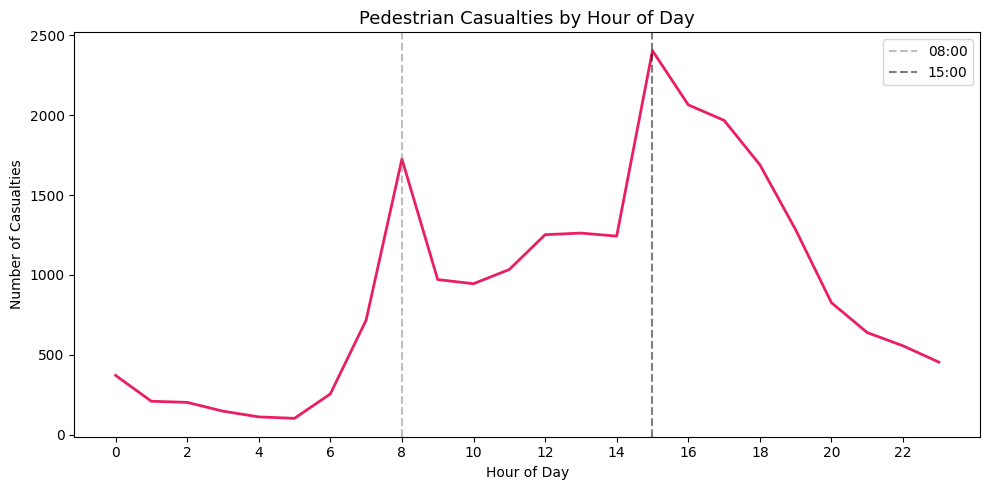

In [28]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(hour_ped['hour'], hour_ped['no_of_accidents'],
        color='#E91E63', linewidth=2)
ax.set_title('Pedestrian Casualties by Hour of Day', fontsize=13)
ax.set_xlabel('Hour of Day')
ax.set_ylabel('Number of Casualties')
ax.set_xticks(range(0, 24, 2))
ax.axvline(x=8, color='grey', linestyle='--', alpha=0.5, label='08:00')
ax.axvline(x=15, color='black', linestyle='--', alpha=0.5, label='15:00')
ax.legend()

plt.tight_layout()
plt.savefig('task3_pedestrian_hourly.png', dpi=150, bbox_inches='tight')
plt.show()

# Heat Map

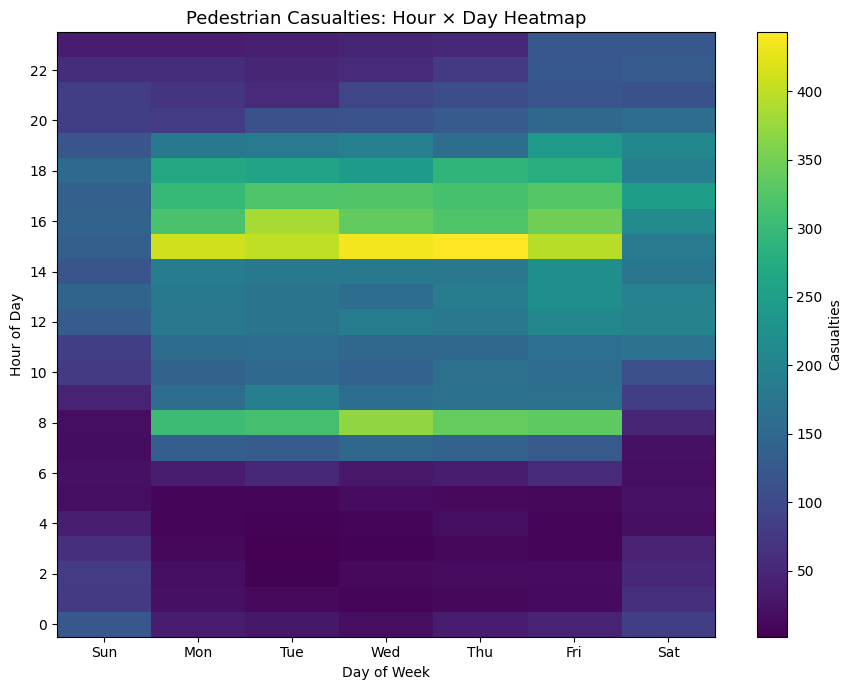

In [29]:
heat_data = (
    ped.groupby(['hour', 'day_of_week'])
       .size()
       .reset_index(name='count')
       .pivot(index='hour', columns='day_of_week', values='count')
       .fillna(0)
)
heat_data.columns = ['Sun','Mon','Tue','Wed','Thu','Fri','Sat']

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(heat_data, aspect='auto', cmap='viridis', origin='lower')
ax.set_title('Pedestrian Casualties: Hour × Day Heatmap', fontsize=13)
ax.set_xlabel('Day of Week')
ax.set_ylabel('Hour of Day')
ax.set_xticks(range(7))
ax.set_xticklabels(['Sun','Mon','Tue','Wed','Thu','Fri','Sat'])
ax.set_yticks(range(0, 24, 2))
ax.set_yticklabels(range(0, 24, 2))
plt.colorbar(im, ax=ax, label='Casualties')

plt.tight_layout()
plt.savefig('task3_pedestrian_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

# Summary Table

In [30]:
ped_summary = pd.DataFrame({
    'Metric': ['Total pedestrian casualties', 
               'Peak hour', 
               'Quietest hour',
               'Peak day', 
               'Quietest day',
               'Hour χ²(23)',
               'Day χ²(6)',
               'Hour p-value',
               'Day p-value'],
    'Value': ['22,432', '15:00 (2,404)', '04:00 (111)',
              'Friday (3,862)', 'Sunday (2,005)',
              '11,226.4', '685.1', '<0.001', '<0.001']
})
ped_summary

,Metric,Value
0,Total pedestrian casualties,"22,432"
1,Peak hour,"15:00 (2,404)"
2,Quietest hour,04:00 (111)
3,Peak day,"Friday (3,862)"
4,Quietest day,"Sunday (2,005)"
5,Hour χ²(23),"11,226.4"
6,Day χ²(6),685.1
7,Hour p-value,<0.001
8,Day p-value,<0.001


# TASK 4

# Load Data

In [32]:
with sqlite3.connect(DB_PATH) as con:
    apriori_df = pd.read_sql(
        """
        SELECT accident_severity,
               speed_limit,
               light_conditions,
               weather_conditions,
               road_surface_conditions,
               urban_or_rural_area,
               junction_detail
        FROM accident
        WHERE accident_year = 2018;
        """,
        con,
    )
print(f"Loaded {len(apriori_df):,} rows")
apriori_df.head()

Loaded 122,635 rows


,accident_severity,speed_limit,light_conditions,weather_conditions,road_surface_conditions,urban_or_rural_area,junction_detail
0,3,30,4,1,1,1,0
1,3,30,4,1,1,1,2
2,3,20,4,1,1,1,6
3,2,30,4,2,2,1,7
4,2,30,4,1,2,1,0


# Define label mappings

In [33]:
severity_map = {1:'Severity=Fatal', 2:'Severity=Serious', 3:'Severity=Slight'}
light_map    = {1:'Light=Daylight', 4:'Light=DarkLit', 5:'Light=DarkUnlit',
                6:'Light=DarkNoLighting', 7:'Light=DarkUnknown'}
weather_map  = {1:'Weather=Fine', 2:'Weather=Raining', 3:'Weather=Snowing',
                4:'Weather=FineHighWinds', 5:'Weather=RainingHighWinds',
                6:'Weather=SnowingHighWinds', 7:'Weather=Fog', 8:'Weather=Other'}
surface_map  = {1:'Surface=Dry', 2:'Surface=Wet', 3:'Surface=Snow',
                4:'Surface=FrostIce', 5:'Surface=Flood'}
urban_map    = {1:'Area=Urban', 2:'Area=Rural'}
junction_map = {0:'Junction=None', 1:'Junction=Roundabout', 2:'Junction=MiniRAB',
                3:'Junction=TorStagger', 5:'Junction=SlipRoad', 6:'Junction=Crossroads',
                7:'Junction=4PlusArms', 8:'Junction=PrivateDrive', 9:'Junction=Other'}

def speed_label(s):
    return f'Speed={int(s)}' if s != -1 else None

print("Label mappings defined")

Label mappings defined


# Build transaction list

Missing values encoded as -1 were excluded at the item level rather than the record level. This ensured all 122,635 accident records contributed to the analysis, with only the specific unrecorded variable omitted from individual transaction baskets, preserving maximum information."

In [34]:
transactions = []
for _, row in apriori_df.iterrows():
    basket = [
        severity_map.get(row['accident_severity']),
        speed_label(row['speed_limit']),
        light_map.get(row['light_conditions']),
        weather_map.get(row['weather_conditions']),
        surface_map.get(row['road_surface_conditions']),
        urban_map.get(row['urban_or_rural_area']),
        junction_map.get(row['junction_detail'])
    ]
    # Remove None values only — keeps all 122,635 accidents
    basket = [item for item in basket if item is not None]
    transactions.append(basket)

print(f"Transactions ready: {len(transactions):,}")
print("Sample transaction:", transactions[0])

Transactions ready: 122,635
Sample transaction: ['Severity=Slight', 'Speed=30', 'Light=DarkLit', 'Weather=Fine', 'Surface=Dry', 'Area=Urban', 'Junction=None']


# Encode transactions into binary matrix

In [35]:
te = TransactionEncoder()
te_array = te.fit_transform(transactions)
basket_df = pd.DataFrame(te_array, columns=te.columns_)

print(f"Basket matrix shape: {basket_df.shape}")
basket_df.head()

Basket matrix shape: (122635, 38)


,Area=Rural,Area=Urban,Junction=4PlusArms,Junction=Crossroads,Junction=MiniRAB,Junction=None,Junction=Other,Junction=PrivateDrive,Junction=Roundabout,Junction=SlipRoad,...,Surface=Snow,Surface=Wet,Weather=Fine,Weather=FineHighWinds,Weather=Fog,Weather=Other,Weather=Raining,Weather=RainingHighWinds,Weather=Snowing,Weather=SnowingHighWinds
0,False,True,False,False,False,True,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False
1,False,True,False,False,True,False,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False
2,False,True,False,True,False,False,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False
3,False,True,True,False,False,False,False,False,False,False,...,False,True,False,False,False,False,True,False,False,False
4,False,True,False,False,False,True,False,False,False,False,...,False,True,True,False,False,False,False,False,False,False


## Run Apriori Algorithm
A minimum support of 0.003 is used to ensure Fatal and Serious severity rules are captured alongside the dominant Slight category. Slight accidents account for 83% of records, so higher support thresholds would suppress Fatal (1.4%) and Serious (18.7%) rules entirely.

In [36]:
# Run apriori with min_support=0.003 to capture Fatal and Serious rules
frequent_itemsets = apriori(basket_df,
                             min_support=0.003,
                             use_colnames=True,
                             max_len=3)

frequent_itemsets['length'] = frequent_itemsets['itemsets'].apply(len)
print(f'Frequent itemsets found: {len(frequent_itemsets):,}')
frequent_itemsets.sort_values('support', ascending=False).head(10)

Frequent itemsets found: 1,223


,support,itemsets,length
29,0.809076,frozenset({Weather=Fine}),1
18,0.799087,frozenset({Severity=Slight}),1
25,0.738337,frozenset({Surface=Dry}),1
15,0.721124,frozenset({Light=Daylight}),1
320,0.700053,"frozenset({Weather=Fine, Surface=Dry})",2
1,0.673405,frozenset({Area=Urban}),1
282,0.642606,"frozenset({Weather=Fine, Severity=Slight})",2
250,0.611710,"frozenset({Weather=Fine, Light=Daylight})",2
20,0.599168,frozenset({Speed=30}),1
278,0.589611,"frozenset({Surface=Dry, Severity=Slight})",2


## Generate All Severity Rules
Rules are filtered to those where severity appears in the consequent, covering Fatal, Serious and Slight outcomes.

In [37]:
# Generate association rules — minimum confidence 0.1
rules = association_rules(frequent_itemsets,
                          metric='confidence',
                          min_threshold=0.1)

# All severity rules — Fatal, Serious and Slight
severity_rules = rules[
    rules['consequents'].astype(str).str.contains('Severity')
].sort_values('lift', ascending=False)

print(f'Total severity rules found: {len(severity_rules):,}')

# Separate by severity type
slight_rules  = severity_rules[severity_rules['consequents'].astype(str).str.contains('Slight')]
serious_fatal = severity_rules[severity_rules['consequents'].astype(str).str.contains('Fatal|Serious')]

print(f'Slight rules: {len(slight_rules):,}')
print(f'Fatal/Serious rules: {len(serious_fatal):,}')

Total severity rules found: 726
Slight rules: 506
Fatal/Serious rules: 220


## Top Rules — Slight Severity

In [38]:
# Top 10 Slight rules by lift 
slight_top = slight_rules.head(10).copy()
slight_top['antecedents'] = slight_top['antecedents'].apply(lambda x: ', '.join(list(x)))
slight_top['consequents'] = slight_top['consequents'].apply(lambda x: ', '.join(list(x)))
slight_top[['support','confidence','lift']] = slight_top[['support','confidence','lift']].round(3)
slight_top = slight_top[['antecedents','consequents','support','confidence','lift']].reset_index(drop=True)
slight_top

,antecedents,consequents,support,confidence,lift
0,Surface=Snow,"Weather=Snowing, Severity=Slight",0.004,0.489,66.213
1,Weather=Snowing,"Surface=Snow, Severity=Slight",0.004,0.500,65.589
2,Junction=SlipRoad,"Speed=70, Severity=Slight",0.005,0.309,6.027
3,Weather=Raining,"Surface=Wet, Severity=Slight",0.082,0.783,4.296
4,Surface=Wet,"Weather=Raining, Severity=Slight",0.082,0.355,4.210
5,Weather=RainingHighWinds,"Surface=Wet, Severity=Slight",0.008,0.738,4.046
6,Speed=60,"Light=DarkNoLighting, Severity=Slight",0.017,0.136,3.946
7,Light=DarkNoLighting,"Speed=60, Severity=Slight",0.017,0.343,3.846
8,Surface=FrostIce,"Speed=60, Severity=Slight",0.003,0.301,3.383
9,Speed=70,"Light=DarkNoLighting, Severity=Slight",0.007,0.104,3.016


## Top Rules- Fatal and Serious Severity
Despite lower support, Fatal and Serious rules are more policy-relevant as they identify conditions associated with the most harmful outcomes.

In [39]:
# Top 10 Fatal/Serious rules by lift — clean table
fs_top = serious_fatal.head(10).copy()
fs_top['antecedents'] = fs_top['antecedents'].apply(lambda x: ', '.join(list(x)))
fs_top['consequents'] = fs_top['consequents'].apply(lambda x: ', '.join(list(x)))
fs_top[['support','confidence','lift']] = fs_top[['support','confidence','lift']].round(3)
fs_top = fs_top[['antecedents','consequents','support','confidence','lift']].reset_index(drop=True)
fs_top

,antecedents,consequents,support,confidence,lift
0,Light=DarkNoLighting,"Speed=60, Severity=Serious",0.007,0.138,4.330
1,Weather=Raining,"Surface=Wet, Severity=Serious",0.018,0.174,3.955
2,Speed=60,"Area=Rural, Severity=Serious",0.031,0.249,3.465
3,Light=DarkNoLighting,"Area=Rural, Severity=Serious",0.012,0.238,3.306
4,Light=DarkNoLighting,"Surface=Wet, Severity=Serious",0.006,0.115,2.603
5,Light=DarkNoLighting,"Junction=None, Severity=Serious",0.010,0.202,2.336
6,Speed=50,"Area=Rural, Severity=Serious",0.007,0.162,2.253
7,Speed=70,"Area=Rural, Severity=Serious",0.010,0.151,2.095
8,Speed=60,"Junction=None, Severity=Serious",0.021,0.167,1.934
9,Area=Rural,"Junction=None, Severity=Serious",0.045,0.137,1.589


## Visualisation - Top Rules by Severity Type

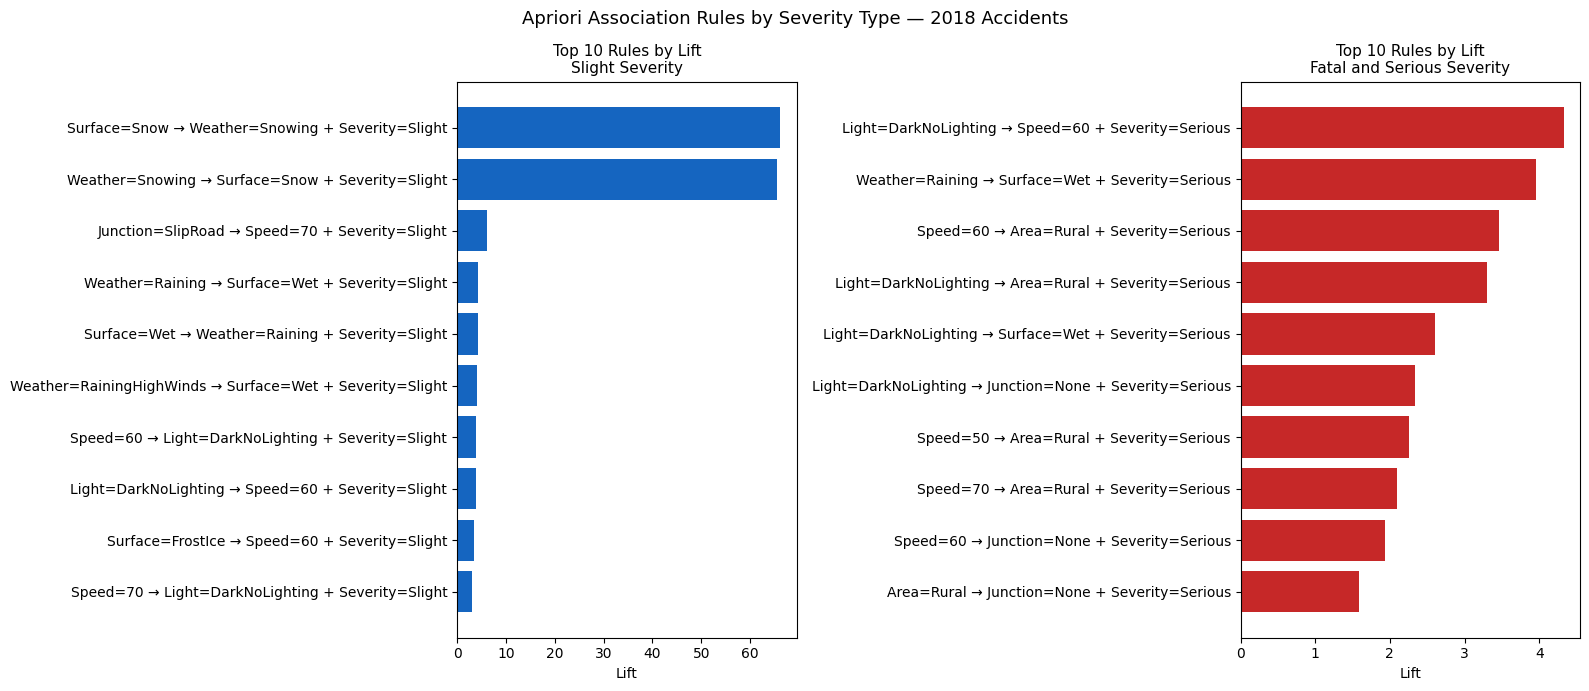

In [41]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# Slight rules chart
slight_plot = slight_rules.head(10).copy()
slight_plot['rule'] = (
    slight_plot['antecedents'].astype(str).str.replace('frozenset','').str.replace("({'",'').str.replace("'})",'') 
    + ' → ' +
    slight_plot['consequents'].astype(str).str.replace('frozenset','').str.replace("({'",'').str.replace("'})",'').str.replace("', '",' + ')
)
ax1.barh(slight_plot['rule'], slight_plot['lift'], color='#1565C0')
ax1.set_xlabel('Lift')
ax1.set_title('Top 10 Rules by Lift\nSlight Severity', fontsize=11)
ax1.invert_yaxis()

# Fatal/Serious rules chart
fs_plot = serious_fatal.head(10).copy()
fs_plot['rule'] = (
    fs_plot['antecedents'].astype(str).str.replace('frozenset','').str.replace("({'",'').str.replace("'})",'') 
    + ' → ' +
    fs_plot['consequents'].astype(str).str.replace('frozenset','').str.replace("({'",'').str.replace("'})",'').str.replace("', '",' + ')
)
ax2.barh(fs_plot['rule'], fs_plot['lift'], color='#C62828')
ax2.set_xlabel('Lift')
ax2.set_title('Top 10 Rules by Lift\nFatal and Serious Severity', fontsize=11)
ax2.invert_yaxis()

plt.suptitle('Apriori Association Rules by Severity Type — 2018 Accidents', fontsize=13)
plt.tight_layout()
plt.savefig('Figure7_Apriori_Rules.png', dpi=150, bbox_inches='tight')
plt.show()

# TASK 5

# Load West Yorkshire data

In [42]:
# Task 5 — West Yorkshire Spatial Clustering
# police_force = 13 confirmed as West Yorkshire from ONS boundary data

with sqlite3.connect(DB_PATH) as con:
    wy = pd.read_sql(
        """
        SELECT accident_index,
               latitude,
               longitude,
               accident_severity,
               lsoa_of_accident_location
        FROM accident
        WHERE accident_year = 2018
          AND police_force = 13;
        """,
        con,
    )

wy.replace(-1, pd.NA, inplace=True)
wy.dropna(subset=['latitude','longitude'], inplace=True)

print(f"West Yorkshire accidents: {len(wy):,}")
wy.head()

West Yorkshire accidents: 4,132


,accident_index,latitude,longitude,accident_severity,lsoa_of_accident_location
0,20181342H0071,53.642853,-1.374243,3,E01011791
1,20181347I1326,53.809110,-1.517027,3,E01011677
2,2018134971519,53.860282,-1.679628,3,E01011276
3,2018134981404,53.805079,-1.548126,3,E01033008
4,2018135110070,53.812706,-1.833560,3,E01010672


# Prepare coordinates for clustering

In [43]:

coords = wy[['latitude', 'longitude']].values
scaler = StandardScaler()
coords_scaled = scaler.fit_transform(coords)

print("Coordinates scaled and ready for clustering")

Coordinates scaled and ready for clustering


# Elbow method

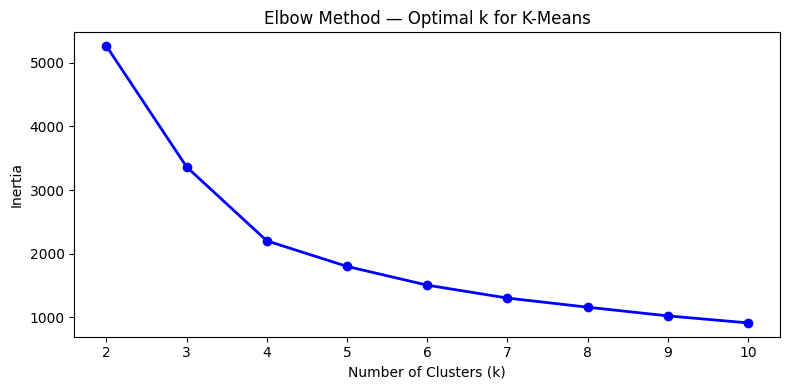

In [44]:

inertias = []
k_range = range(2, 11)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(coords_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(list(k_range), inertias, 'bo-', linewidth=2)
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method — Optimal k for K-Means')
plt.xticks(list(k_range))
plt.tight_layout()
plt.show()

# K-Means with k=5

In [45]:
# K-Means with k=5 — justified by elbow method and WY 5 metropolitan districts
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
wy['kmeans_cluster'] = kmeans.fit_predict(coords_scaled)

kmeans_summary = (
    wy.groupby('kmeans_cluster')
      .agg(
          no_of_accidents=('accident_index', 'count'),
          centre_lat=('latitude', 'mean'),
          centre_lon=('longitude', 'mean')
      )
      .round(3)
      .reset_index()
)
kmeans_summary

,kmeans_cluster,no_of_accidents,centre_lat,centre_lon
0,0,753,53.704,-1.587
1,1,1219,53.808,-1.535
2,2,369,53.676,-1.336
3,3,1109,53.817,-1.775
4,4,682,53.671,-1.831


# K-Means severity breakdown

In [46]:
# Severity as frequency counts — not mean (severity is ordinal categorical)
severity_labels = {1: 'Fatal', 2: 'Serious', 3: 'Slight'}

kmeans_sev = (
    wy.groupby(['kmeans_cluster', 'accident_severity'])
      .size()
      .reset_index(name='count')
)
kmeans_sev['severity_label'] = kmeans_sev['accident_severity'].map(severity_labels)

kmeans_sev_pivot = kmeans_sev.pivot(
    index='kmeans_cluster',
    columns='severity_label',
    values='count'
).fillna(0).astype(int).reset_index()

kmeans_sev_pivot.columns.name = None
kmeans_sev_pivot['Total'] = kmeans_sev_pivot[['Fatal','Serious','Slight']].sum(axis=1)
kmeans_sev_pivot

,kmeans_cluster,Fatal,Serious,Slight,Total
0,0,13,135,605,753
1,1,16,226,977,1219
2,2,10,81,278,369
3,3,16,182,911,1109
4,4,8,115,559,682


# DBSCAN

In [47]:

dbscan = DBSCAN(eps=0.1, min_samples=15)
wy['dbscan_cluster'] = dbscan.fit_predict(coords_scaled)

n_clusters = len(set(wy['dbscan_cluster'])) - 1
n_noise = (wy['dbscan_cluster'] == -1).sum()

print(f"DBSCAN clusters found: {n_clusters} (excluding noise)")
print(f"Noise points: {n_noise} ({n_noise/len(wy)*100:.1f}%)")

dbscan_summary = (
    wy.groupby('dbscan_cluster')
      .agg(
          no_of_accidents=('accident_index', 'count'),
          centre_lat=('latitude', 'mean'),
          centre_lon=('longitude', 'mean')
      )
      .round(3)
      .reset_index()
)
dbscan_summary['cluster_label'] = dbscan_summary['dbscan_cluster'].apply(
    lambda x: 'Noise' if x == -1 else f'Cluster {x}')
dbscan_summary = dbscan_summary[['cluster_label','no_of_accidents',
                                  'centre_lat','centre_lon']]
dbscan_summary

DBSCAN clusters found: 22 (excluding noise)
Noise points: 1111 (26.9%)


,cluster_label,no_of_accidents,centre_lat,centre_lon
0,Noise,1111,53.733,-1.622
1,Cluster 0,1092,53.798,-1.545
2,Cluster 1,206,53.650,-1.789
3,Cluster 2,137,53.739,-1.621
4,Cluster 3,47,53.700,-1.769
5,Cluster 4,81,53.866,-1.908
6,Cluster 5,736,53.798,-1.758
7,Cluster 6,30,53.833,-1.650
8,Cluster 7,140,53.681,-1.506
9,Cluster 8,16,53.906,-1.694


# DBSCAN severity breakdown

In [48]:
# DBSCAN severity breakdown — frequency counts not mean
dbscan_sev = (
    wy[wy['dbscan_cluster'] != -1]
      .groupby(['dbscan_cluster', 'accident_severity'])
      .size()
      .reset_index(name='count')
)
dbscan_sev['severity_label'] = dbscan_sev['accident_severity'].map(severity_labels)
dbscan_sev['cluster_label'] = 'Cluster ' + dbscan_sev['dbscan_cluster'].astype(str)

dbscan_sev_pivot = dbscan_sev.pivot_table(
    index='cluster_label',
    columns='severity_label',
    values='count',
    fill_value=0
).astype(int).reset_index()

dbscan_sev_pivot.columns.name = None
dbscan_sev_pivot['Total'] = dbscan_sev_pivot[['Fatal','Serious','Slight']].sum(axis=1)
dbscan_sev_pivot.sort_values('Total', ascending=False).reset_index(drop=True)

,cluster_label,Fatal,Serious,Slight,Total
0,Cluster 0,12,192,888,1092
1,Cluster 5,6,103,627,736
2,Cluster 1,1,28,177,206
3,Cluster 10,2,23,119,144
4,Cluster 7,2,24,114,140
5,Cluster 2,2,21,114,137
6,Cluster 9,1,22,100,123
7,Cluster 4,1,13,67,81
8,Cluster 14,1,13,34,48
9,Cluster 3,1,4,42,47


# Side by side visualisation

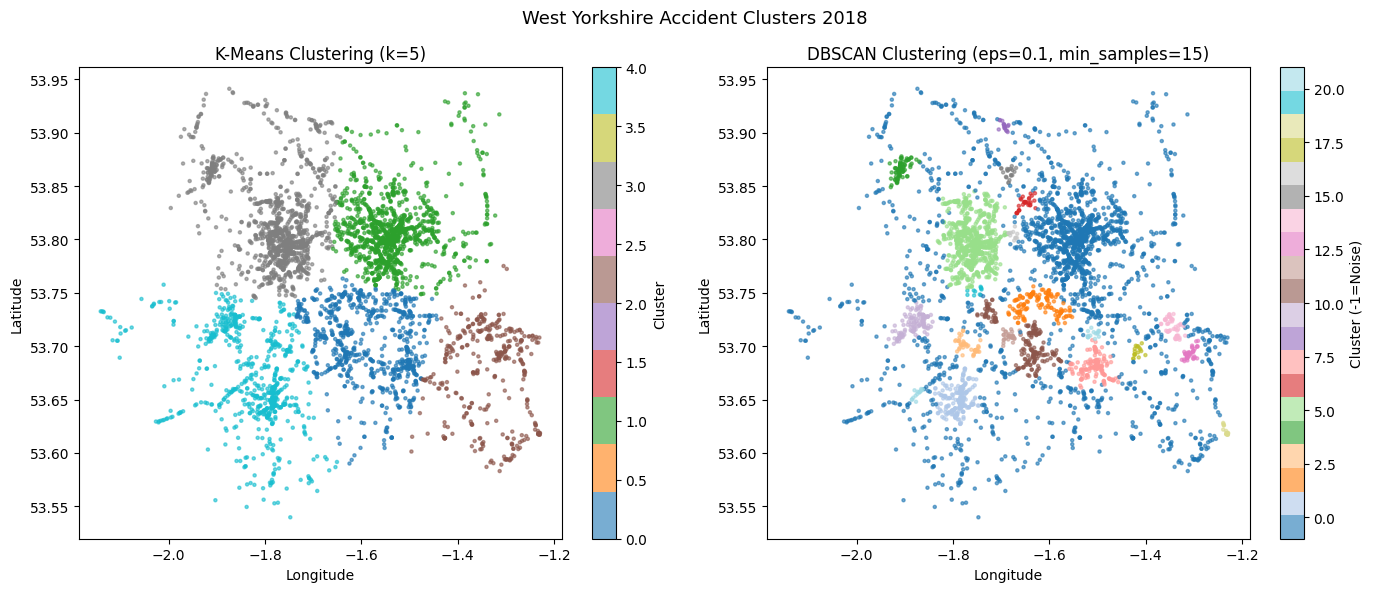

Figure 8 saved


In [49]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# K-Means plot
scatter1 = ax1.scatter(wy['longitude'], wy['latitude'],
                       c=wy['kmeans_cluster'], cmap='tab10',
                       s=5, alpha=0.6)
ax1.set_title('K-Means Clustering (k=5)', fontsize=12)
ax1.set_xlabel('Longitude')
ax1.set_ylabel('Latitude')
plt.colorbar(scatter1, ax=ax1, label='Cluster')

# DBSCAN plot
colors = wy['dbscan_cluster'].apply(lambda x: -1 if x == -1 else x)
scatter2 = ax2.scatter(wy['longitude'], wy['latitude'],
                       c=colors, cmap='tab20',
                       s=5, alpha=0.6)
ax2.set_title('DBSCAN Clustering (eps=0.1, min_samples=15)', fontsize=12)
ax2.set_xlabel('Longitude')
ax2.set_ylabel('Latitude')
plt.colorbar(scatter2, ax=ax2, label='Cluster (-1=Noise)')

plt.suptitle('West Yorkshire Accident Clusters 2018', fontsize=13)
plt.tight_layout()
plt.savefig('Figure8_WY_Clustering.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figure 8 saved")

# TASK 6

## Load weekly data for three forces

In [50]:
# Time Series: Weekly accident counts
# Three police forces: 1=Metropolitan, 13=West Yorkshire, 46=Thames Valley

FORCES = {1: 'Metropolitan', 13: 'West Yorkshire', 46: 'Thames Valley'}

with sqlite3.connect(DB_PATH) as con:
    ts_df = pd.read_sql(
        """
        SELECT police_force, date, accident_year
        FROM accident
        WHERE accident_year IN (2017, 2018, 2019)
          AND police_force IN (1, 13, 46);
        """,
        con,
    )

ts_df['date'] = pd.to_datetime(ts_df['date'], dayfirst=True)
ts_df['week'] = ts_df['date'].dt.to_period('W').apply(lambda r: r.start_time)

weekly = (
    ts_df.groupby(['police_force', 'week'])
         .size()
         .reset_index(name='accident_count')
)
weekly['force_name'] = weekly['police_force'].map(FORCES)
weekly = weekly[weekly['week'] >= '2017-01-01'].reset_index(drop=True)

print(f"Weekly records: {len(weekly):,}")
weekly.head()

Weekly records: 471


,police_force,week,accident_count,force_name
0,1,2017-01-02,453,Metropolitan
1,1,2017-01-09,535,Metropolitan
2,1,2017-01-16,566,Metropolitan
3,1,2017-01-23,513,Metropolitan
4,1,2017-01-30,460,Metropolitan


## Visualise weekly counts

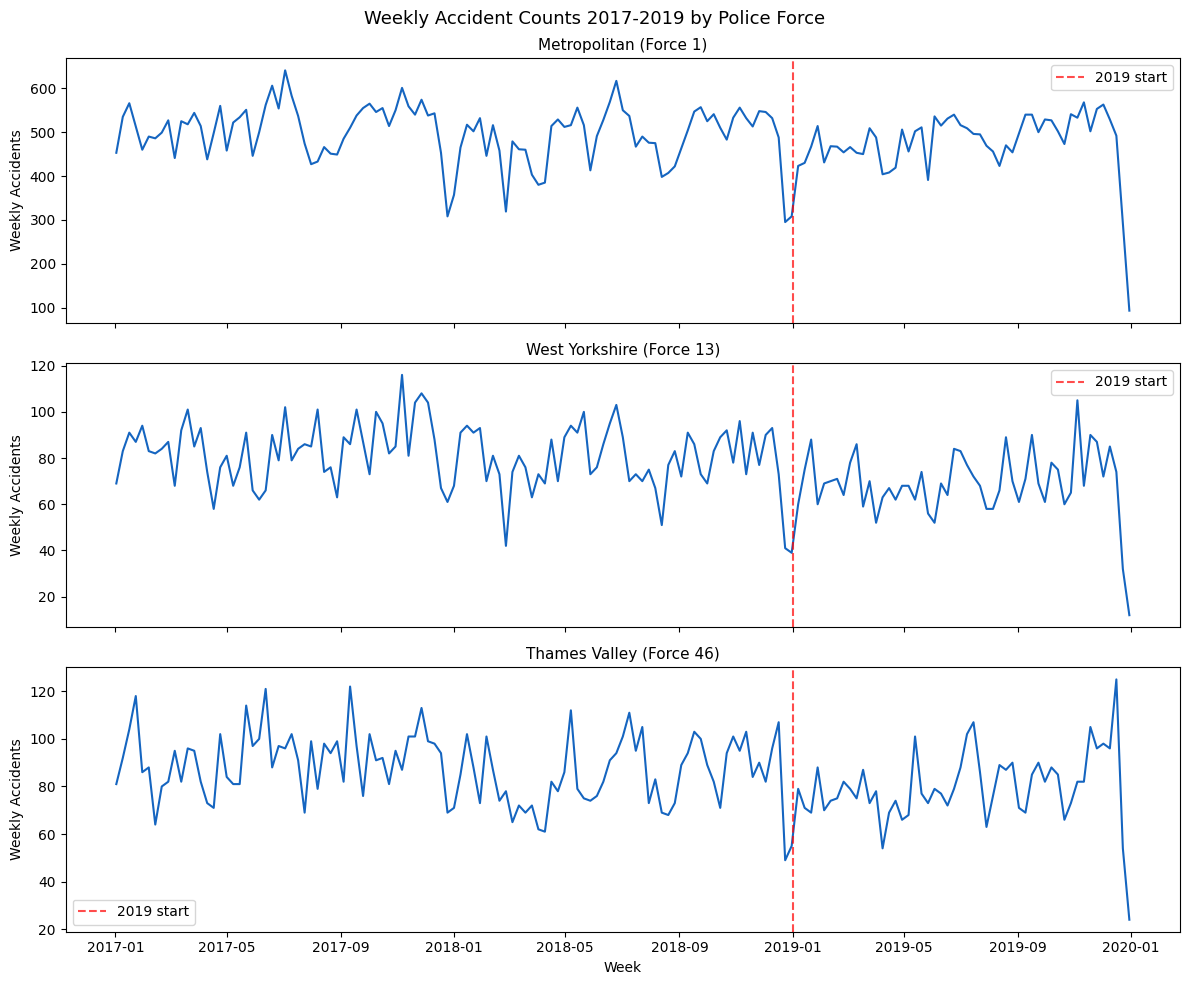

In [51]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

for ax, (force_id, force_name) in zip(axes, FORCES.items()):
    subset = weekly[weekly['police_force'] == force_id]
    ax.plot(subset['week'], subset['accident_count'],
            linewidth=1.5, color='#1565C0')
    ax.set_title(f'{force_name} (Force {force_id})', fontsize=11)
    ax.set_ylabel('Weekly Accidents')
    ax.axvline(pd.Timestamp('2019-01-01'), color='red',
               linestyle='--', alpha=0.7, label='2019 start')
    ax.legend()

axes[-1].set_xlabel('Week')
plt.suptitle('Weekly Accident Counts 2017-2019 by Police Force', fontsize=13)
plt.tight_layout()
plt.show()

## Train/test split

In [62]:
# Train: 2017-2018, Test: 2019
results = {}

for force_id, force_name in FORCES.items():
    subset = (weekly[weekly['police_force'] == force_id]
              .sort_values('week')
              .set_index('week')['accident_count'])
    
    train = subset[subset.index.year.isin([2017, 2018])].copy()
    train.index.freq = 'W-MON'
    test = subset[subset.index.year == 2019].copy()
    test.index.freq = 'W-MON'
    
    results[force_id] = {
        'name': force_name,
        'series': subset,
        'train': train,
        'test': test
    }
    print(f"{force_name}: train={len(train)} weeks, test={len(test)} weeks")

Metropolitan: train=105 weeks, test=52 weeks
West Yorkshire: train=105 weeks, test=52 weeks
Thames Valley: train=105 weeks, test=52 weeks


## ADF stationarity test

In [63]:

print("ADF Stationarity Tests — Training Series:")
adf_results = []

for force_id, data in results.items():
    adf_stat, p_val = adfuller(data['train'])[:2]
    adf_results.append({
        'Force': data['name'],
        'ADF Statistic': round(adf_stat, 3),
        'p-value': round(p_val, 3),
        'Result': 'Stationary' if p_val < 0.05 else 'Non-stationary (d=1 needed)'
    })

pd.DataFrame(adf_results)

ADF Stationarity Tests — Training Series:


,Force,ADF Statistic,p-value,Result
0,Metropolitan,-4.645,0.0,Stationary
1,West Yorkshire,-6.382,0.0,Stationary
2,Thames Valley,-6.780,0.0,Stationary


## SARIMA AIC grid search

In [64]:

import itertools

def fit_sarima(train, order, seasonal_order):
    try:
        model = SARIMAX(train, order=order,
                        seasonal_order=seasonal_order,
                        enforce_stationarity=False,
                        enforce_invertibility=False)
        result = model.fit(disp=False)
        return result.aic
    except:
        return np.inf

# Grid search — p,q in 0-2, P,Q in 0-1, d=1, D=1, m=52
best_params = {}
aic_summary = []

for force_id, data in results.items():
    print(f"Searching {data['name']}...")
    train = data['train']
    best_aic = np.inf
    best = None

    for p, q, P, Q in itertools.product(range(3), range(3),
                                         range(2), range(2)):
        aic = fit_sarima(train, (p, 1, q), (P, 1, Q, 52))
        if aic < best_aic:
            best_aic = aic
            best = (p, q, P, Q)

    best_params[force_id] = best
    aic_summary.append({
        'Force': data['name'],
        'Best order': f'({best[0]},1,{best[1]})',
        'Seasonal order': f'({best[2]},1,{best[3]},52)',
        'AIC': round(best_aic, 1)
    })
    print(f"  Best: SARIMA({best[0]},1,{best[1]})({best[2]},1,{best[3]},52) AIC={best_aic:.1f}")

print("\nAIC Summary:")
pd.DataFrame(aic_summary)

Searching Metropolitan...
  Best: SARIMA(0,1,0)(0,1,1,52) AIC=4.0
Searching West Yorkshire...
  Best: SARIMA(0,1,0)(0,1,1,52) AIC=4.0
Searching Thames Valley...
  Best: SARIMA(0,1,0)(0,1,1,52) AIC=4.0

AIC Summary:


,Force,Best order,Seasonal order,AIC
0,Metropolitan,"(0,1,0)","(0,1,1,52)",4.0
1,West Yorkshire,"(0,1,0)","(0,1,1,52)",4.0
2,Thames Valley,"(0,1,0)","(0,1,1,52)",4.0


## Fit SARIMA and forecast

In [65]:
sarima_forecasts = {}

for force_id, data in results.items():
    p, q, P, Q = best_params[force_id]
    train = data['train']
    test  = data['test']

    model = SARIMAX(train,
                    order=(p, 1, q),
                    seasonal_order=(P, 1, Q, 52),
                    enforce_stationarity=False,
                    enforce_invertibility=False)
    fitted = model.fit(disp=False)

    forecast = fitted.get_forecast(steps=len(test))
    sarima_forecasts[force_id] = {
        'predicted': forecast.predicted_mean.values,
        'actual': test.values,
        'index': test.index
    }
    print(f"{data['name']} SARIMA fitted")

Metropolitan SARIMA fitted
West Yorkshire SARIMA fitted
Thames Valley SARIMA fitted


## XGBoost features and forecast

In [66]:

def make_features(series):
    df = series.to_frame(name='y')
    df['week_of_year'] = df.index.isocalendar().week.astype(int)
    df['month']        = df.index.month
    df['trend']        = range(len(df))
    for lag in [1, 2, 3, 52]:
        df[f'lag_{lag}'] = df['y'].shift(lag)
    return df.dropna()

xgb_forecasts = {}

for force_id, data in results.items():
    series = data['series']
    feat_df = make_features(series)

    X = feat_df.drop('y', axis=1)
    y = feat_df['y']

    train_mask = feat_df.index.year.isin([2017, 2018])
    test_mask  = feat_df.index.year == 2019

    X_train, y_train = X[train_mask], y[train_mask]
    X_test,  y_test  = X[test_mask],  y[test_mask]

    xgb = XGBRegressor(n_estimators=100, learning_rate=0.1,
                       max_depth=5, random_state=42)
    xgb.fit(X_train, y_train)

    xgb_forecasts[force_id] = {
        'predicted': xgb.predict(X_test),
        'actual': y_test.values,
        'index': y_test.index
    }
    print(f"{data['name']} XGBoost fitted")

Metropolitan XGBoost fitted
West Yorkshire XGBoost fitted
Thames Valley XGBoost fitted


## Plot predictions vs actual

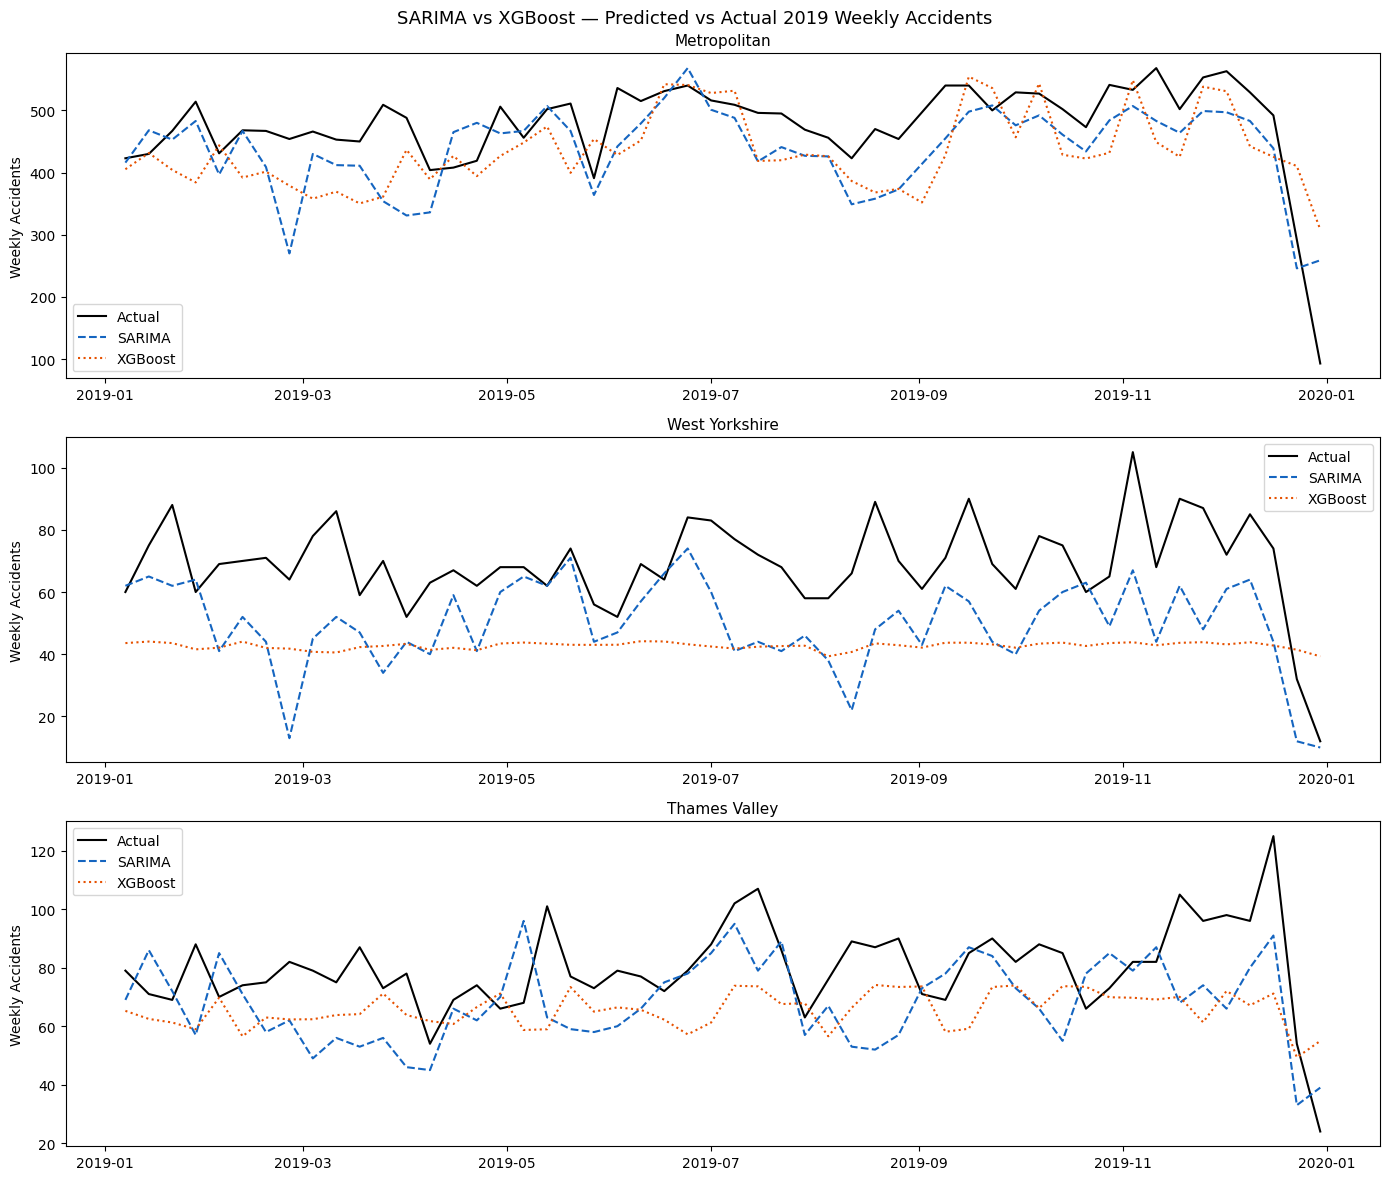

Figure 9 saved


In [67]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=False)

for ax, (force_id, force_name) in zip(axes, FORCES.items()):
    idx      = sarima_forecasts[force_id]['index']
    actual   = sarima_forecasts[force_id]['actual']
    sarima   = sarima_forecasts[force_id]['predicted']
    xgb_pred = xgb_forecasts[force_id]['predicted']

    ax.plot(idx, actual,   label='Actual',  color='black',   linewidth=1.5)
    ax.plot(idx, sarima,   label='SARIMA',  color='#1565C0', linestyle='--', linewidth=1.5)
    ax.plot(idx, xgb_pred, label='XGBoost', color='#E65100', linestyle=':',  linewidth=1.5)
    ax.set_title(force_name, fontsize=11)
    ax.set_ylabel('Weekly Accidents')
    ax.legend()

plt.suptitle('SARIMA vs XGBoost — Predicted vs Actual 2019 Weekly Accidents', fontsize=13)
plt.tight_layout()
plt.savefig('Figure9_TimeSeries.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figure 9 saved")

## Metrics comparison table

In [68]:
metrics_rows = []

for force_id, force_name in FORCES.items():
    for model_name, forecasts in [('SARIMA', sarima_forecasts),
                                   ('XGBoost', xgb_forecasts)]:
        actual    = forecasts[force_id]['actual']
        predicted = forecasts[force_id]['predicted']
        row = compute_metrics(actual, predicted,
                              label=f"{force_name} — {model_name}")
        metrics_rows.append(row)

metrics_df = pd.concat(metrics_rows, ignore_index=True)
print("Model Performance Comparison:")
metrics_df

Model Performance Comparison:


,Model,MSE,RMSE,MAPE (%)
0,Metropolitan — SARIMA,4539.27,67.37,14.03
1,Metropolitan — XGBoost,6109.40,78.16,16.89
2,West Yorkshire — SARIMA,540.15,23.24,27.94
3,West Yorkshire — XGBoost,886.55,29.77,41.76
4,Thames Valley — SARIMA,402.15,20.05,20.72
5,Thames Valley — XGBoost,391.84,19.79,20.76


# TASK 7

## Load West Yorkshire 2018 data

In [69]:
# Task 7 — Top 30 WY LSOAs daily time series forecast

with sqlite3.connect(DB_PATH) as con:
    wy_2018 = pd.read_sql(
        """
        SELECT accident_index, date, lsoa_of_accident_location
        FROM accident
        WHERE accident_year = 2018
          AND police_force = 13;
        """,
        con,
    )

wy_2018['date'] = pd.to_datetime(wy_2018['date'], dayfirst=True)
wy_2018 = wy_2018.dropna(subset=['lsoa_of_accident_location'])

print(f"West Yorkshire 2018 accidents: {len(wy_2018):,}")
wy_2018.head()

West Yorkshire 2018 accidents: 4,132


,accident_index,date,lsoa_of_accident_location
0,20181342H0071,2018-02-17,E01011791
1,20181347I1326,2018-02-18,E01011677
2,2018134971519,2018-02-07,E01011276
3,2018134981404,2018-02-08,E01033008
4,2018135110070,2018-01-01,E01010672


## Identify top 30 LSOAs by Q1 accident count

In [70]:
# Filter Jan-Mar 2018 and find top 30 LSOAs
q1 = wy_2018[wy_2018['date'].dt.month.isin([1, 2, 3])]

top30_lsoas = (
    q1.groupby('lsoa_of_accident_location')
      .size()
      .reset_index(name='q1_count')
      .sort_values('q1_count', ascending=False)
      .head(30)
)

top30_list = top30_lsoas['lsoa_of_accident_location'].tolist()

print(f"Top 30 LSOAs identified")
print(f"Total Q1 accidents in top 30: {top30_lsoas['q1_count'].sum():,}")
top30_lsoas.head(10)

Top 30 LSOAs identified
Total Q1 accidents in top 30: 164


,lsoa_of_accident_location,q1_count
377,E01011499,11
208,E01011107,8
568,E01033010,8
584,E01033693,8
325,E01011369,7
99,E01010833,7
258,E01011236,7
565,E01033005,6
405,E01011569,6
543,E01011935,6


## Aggregate daily counts Jan-Jun 2018

In [71]:
# Filter to top 30 LSOAs, Jan-Jun 2018
jan_jun = wy_2018[
    (wy_2018['lsoa_of_accident_location'].isin(top30_list)) &
    (wy_2018['date'].dt.month.isin([1, 2, 3, 4, 5, 6]))
]

# Daily accident counts
daily = (
    jan_jun.groupby('date')
           .size()
           .reset_index(name='accident_count')
           .sort_values('date')
)

# Fill missing dates with 0
full_range = pd.date_range(start='2018-01-01', end='2018-06-30', freq='D')
daily = daily.set_index('date').reindex(full_range, fill_value=0).reset_index()
daily.columns = ['date', 'accident_count']

print(f"Daily records Jan-Jun 2018: {len(daily)}")
print(f"Total accidents: {daily['accident_count'].sum()}")
print(f"Mean per day: {daily['accident_count'].mean():.2f}")
daily.head()

Daily records Jan-Jun 2018: 181
Total accidents: 276
Mean per day: 1.52


,date,accident_count
0,2018-01-01,2
1,2018-01-02,2
2,2018-01-03,2
3,2018-01-04,1
4,2018-01-05,1


## Visualise daily series

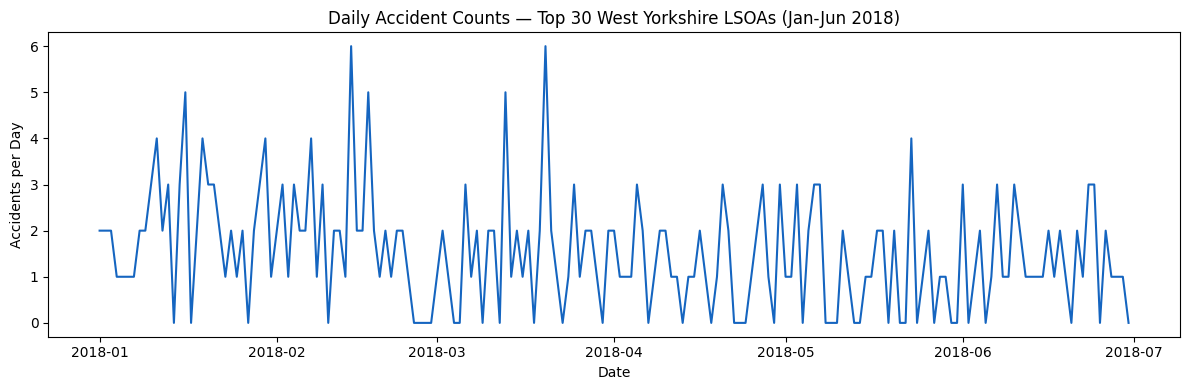

Figure 10 saved


In [80]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(daily['date'], daily['accident_count'],
        color='#1565C0', linewidth=1.5)
ax.set_title('Daily Accident Counts — Top 30 West Yorkshire LSOAs (Jan-Jun 2018)')
ax.set_xlabel('Date')
ax.set_ylabel('Accidents per Day')
plt.tight_layout()
plt.savefig('Figure10_Daily_Series.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figure 10 saved")

## ADF stationarity test

In [73]:

series = daily.set_index('date')['accident_count']
adf_stat, p_val = adfuller(series)[:2]

print(f"ADF Statistic: {adf_stat:.4f}")
print(f"p-value: {p_val:.4f}")
print(f"Conclusion: {'Stationary' if p_val < 0.05 else 'Non-stationary'}")

ADF Statistic: -3.1803
p-value: 0.0212
Conclusion: Stationary


## SARIMA AIC grid search

In [75]:

# Grid search — m=7 for weekly seasonality in daily data
best_aic = np.inf
best_params = None
aic_results = []

for p in range(0, 3):
    for q in range(0, 3):
        for P in range(0, 2):
            for Q in range(0, 2):
                try:
                    model = SARIMAX(series,
                                    order=(p, 0, q),
                                    seasonal_order=(P, 1, Q, 7),
                                    enforce_stationarity=False,
                                    enforce_invertibility=False)
                    result = model.fit(disp=False)
                    aic_results.append({
                        'p': p, 'q': q, 'P': P, 'Q': Q,
                        'AIC': round(result.aic, 2)
                    })
                    if result.aic < best_aic:
                        best_aic = result.aic
                        best_params = (p, 0, q, P, 1, Q, 7)
                except:
                    continue

aic_df = pd.DataFrame(aic_results).sort_values('AIC').head(10).reset_index(drop=True)
print(f"Best params: order={best_params[:3]}, seasonal={best_params[3:]}")
print(f"Best AIC: {best_aic:.2f}")
aic_df

C:\Users\960944\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\960944\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\960944\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\960944\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\960944\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473

Best params: order=(1, 0, 2), seasonal=(0, 1, 1, 7)
Best AIC: 554.71


C:\Users\960944\AppData\Roaming\Python\Python313\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


,p,q,P,Q,AIC
0,1,2,0,1,554.71
1,2,2,0,1,555.82
2,1,2,1,1,556.71
3,2,2,1,1,557.82
4,2,1,0,1,558.36
5,1,1,0,1,558.85
6,0,2,0,1,560.27
7,2,1,1,1,560.36
8,1,1,1,1,560.85
9,0,2,1,1,562.27


## Fit SARIMA and forecast July 2018

In [76]:
# Fit final SARIMA model
final_model = SARIMAX(series,
                      order=(best_params[0], best_params[1], best_params[2]),
                      seasonal_order=(best_params[3], best_params[4],
                                      best_params[5], best_params[6]),
                      enforce_stationarity=False,
                      enforce_invertibility=False)
sarima_fit = final_model.fit(disp=False)
print(sarima_fit.summary())

# Forecast July 2018 (31 days)
forecast = sarima_fit.get_forecast(steps=31)
forecast_mean = forecast.predicted_mean
forecast_ci = forecast.conf_int()

july_dates = pd.date_range(start='2018-07-01', end='2018-07-31', freq='D')
forecast_mean.index = july_dates
forecast_ci.index = july_dates

C:\Users\960944\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\960944\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


                                      SARIMAX Results                                      
Dep. Variable:                      accident_count   No. Observations:                  181
Model:             SARIMAX(1, 0, 2)x(0, 1, [1], 7)   Log Likelihood                -272.353
Date:                             Mon, 04 May 2026   AIC                            554.706
Time:                                     21:59:03   BIC                            570.205
Sample:                                 01-01-2018   HQIC                           560.998
                                      - 06-30-2018                                         
Covariance Type:                               opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.7570      0.107     -7.051      0.000      -0.967      -0.547
ma.L1          0.8112      

## Get actual July data

In [77]:
# Get actual July 2018 daily counts for top 30 LSOAs
with sqlite3.connect(DB_PATH) as con:
    july_full = pd.read_sql(
        """
        SELECT date, lsoa_of_accident_location
        FROM accident
        WHERE accident_year = 2018
          AND police_force = 13;
        """,
        con,
    )

july_full['date'] = pd.to_datetime(july_full['date'], dayfirst=True)
july_top30 = july_full[
    (july_full['date'].dt.month == 7) &
    (july_full['lsoa_of_accident_location'].isin(top30_list))
]

july_counts = (
    july_top30.groupby('date')
              .size()
              .reset_index(name='actual')
              .set_index('date')
              .reindex(july_dates, fill_value=0)
)

print(f"July actual total: {july_counts['actual'].sum()}")
print(f"July actual mean per day: {july_counts['actual'].mean():.2f}")
july_counts.head()

July actual total: 30
July actual mean per day: 0.97


,actual
2018-07-01,1
2018-07-02,4
2018-07-03,3
2018-07-04,0
2018-07-05,0


## Plot forecast vs actual

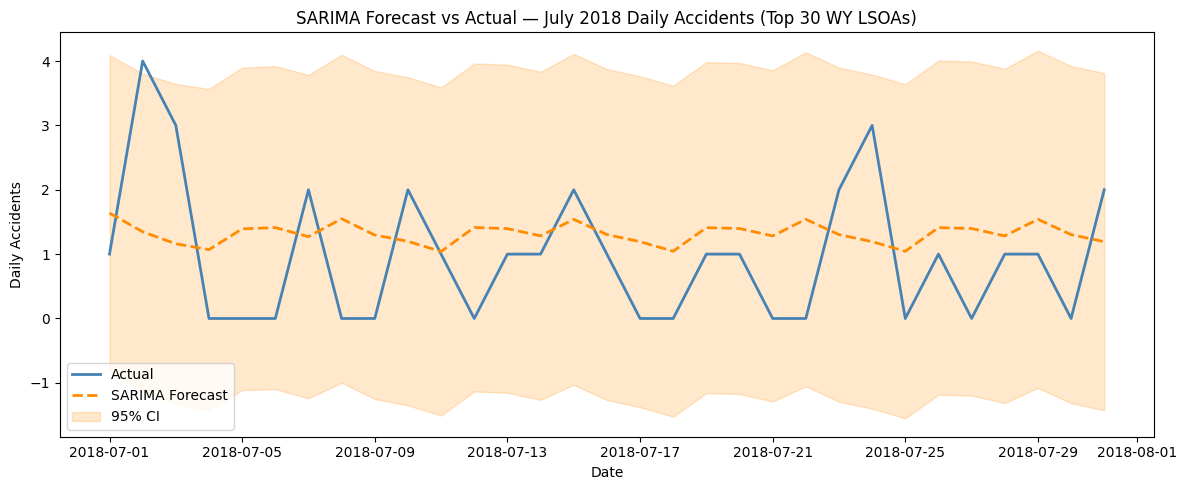

Figure 11 saved


In [81]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(july_dates, july_counts['actual'],
        label='Actual', color='steelblue', linewidth=2)
ax.plot(july_dates, forecast_mean.values,
        label='SARIMA Forecast', color='darkorange',
        linestyle='--', linewidth=2)
ax.fill_between(july_dates,
                forecast_ci.iloc[:, 0],
                forecast_ci.iloc[:, 1],
                alpha=0.2, color='darkorange', label='95% CI')
ax.set_title('SARIMA Forecast vs Actual — July 2018 Daily Accidents (Top 30 WY LSOAs)')
ax.set_xlabel('Date')
ax.set_ylabel('Daily Accidents')
ax.legend()
plt.tight_layout()
plt.savefig('Figure11_Task7_Forecast.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figure 11 saved")

## Performance metrics

In [79]:
actual_vals   = july_counts['actual'].values
forecast_vals = forecast_mean.values

print("SARIMA Forecast Performance — July 2018")
compute_metrics(actual_vals, forecast_vals, label='SARIMA — Task 7')

SARIMA Forecast Performance — July 2018


,Model,MSE,RMSE,MAPE (%)
0,SARIMA — Task 7,1.3,1.14,40.73
